# TRASHURY — Training Model Klasifikasi Sampah

Notebook ini melatih model klasifikasi gambar sampah untuk fitur **Klasifikasi Sampah dari Foto** pada aplikasi TRASHURY, lalu meng-export model terbaik ke format **ONNX** untuk dipakai di aplikasi desktop WPF (C#).

**Alur notebook ini:**
1. Setup & instalasi package
2. Download dataset dari Roboflow
3. Filter dataset (hanya kelas single-label dengan data cukup)
4. Preprocessing & augmentasi
5. Training & perbandingan 3 arsitektur (ResNet18, ResNet34, EfficientNet-B0)
6. Evaluasi lengkap (classification report, confusion matrix, training curve, contoh salah klasifikasi)
7. Test-Time Augmentation (TTA)
8. Export model terbaik ke ONNX + label kelas

## 1. Setup & Instalasi Package

In [ ]:
!pip install roboflow torch torchvision scikit-learn matplotlib seaborn onnx onnxscript -q

import os
import time
import shutil
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.7 MB/s eta 0:00:00
Menggunakan device: cuda


## 2. Download Dataset dari Roboflow

Ganti cell di bawah dengan kode download yang kamu dapatkan dari halaman **Download** project Roboflow (format **Folder Structure**).

In [ ]:
import os
from getpass import getpass
from roboflow import Roboflow

api_key = os.environ.get("ROBOFLOW_API_KEY") or getpass("Masukkan Roboflow API Key: ")
rf = Roboflow(api_key=api_key)
project = rf.workspace("mirzach89-gmail-com").project("waste-classification-rjo28-2limn")
version = project.version(3)
dataset = version.download("folder")

dataset_path = dataset.location
print("Lokasi dataset:", dataset_path)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to waste-classification-3 in folder:: 100%|██████████| 2420/2420 [00:00<00:00, 2770.64it/s]

Lokasi dataset: /content/waste-classification-3


## 3. Filter Dataset

Dataset hasil fork bersifat *multi-label* (nama folder gabungan beberapa kelas). Sel ini menyaring hanya folder **single-label** dengan jumlah data yang memadai (12 kelas terpilih).

In [ ]:
kelas_dipakai = [
    'Paper', 'Plastic Bottle', 'Plastic bag', 'Paper Cup', 'Paper Bag',
    'food waste', 'Plastic Cup', 'Cardboard Boxes', 'Glass Bottles',
    'Glass Shards', 'Jug', 'Metal Can'
]

filtered_path = "/content/dataset_filtered"

for split in ['train', 'valid', 'test']:
    for kelas in kelas_dipakai:
        src = os.path.join(dataset_path, split, kelas)
        dst = os.path.join(filtered_path, split, kelas)
        if os.path.exists(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)

print("Selesai filter dataset.\n")
for split in ['train', 'valid', 'test']:
    split_path = os.path.join(filtered_path, split)
    total = sum(len(os.listdir(os.path.join(split_path, k))) for k in os.listdir(split_path))
    print(f"{split}: {len(os.listdir(split_path))} kelas, {total} gambar")

Selesai filter dataset.

train: 12 kelas, 1556 gambar
valid: 12 kelas, 400 gambar
test: 12 kelas, 207 gambar


## 4. Preprocessing & Augmentasi

Data training diaugmentasi cukup agresif (crop, flip, rotasi, perubahan warna) supaya model lebih tahan terhadap variasi foto asli di lapangan. Data valid/test **tidak** diaugmentasi agar evaluasi tetap konsisten.

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.15))
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_ds = datasets.ImageFolder(f"{filtered_path}/train", transform=train_transform)
valid_ds = datasets.ImageFolder(f"{filtered_path}/valid", transform=eval_transform)
test_ds  = datasets.ImageFolder(f"{filtered_path}/test", transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=32)
test_loader  = DataLoader(test_ds, batch_size=32)

num_classes = len(train_ds.classes)
print("Jumlah kelas:", num_classes)
print("Daftar kelas:", train_ds.classes)

# Class weight untuk mengatasi ketimpangan jumlah data antar kelas
class_counts = Counter([label for _, label in train_ds.samples])
class_weights = torch.tensor([
    1.0 / class_counts[i] for i in range(num_classes)
], dtype=torch.float32).to(device)
class_weights = class_weights / class_weights.sum() * num_classes
print("Class weights:", class_weights)

Jumlah kelas: 12
Daftar kelas: ['Cardboard Boxes', 'Glass Bottles', 'Glass Shards', 'Jug', 'Metal Can', 'Paper', 'Paper Bag', 'Paper Cup', 'Plastic Bottle', 'Plastic Cup', 'Plastic bag', 'food waste']
Class weights: tensor([0.6420, 0.7877, 1.3711, 1.0097, 0.7212, 1.4808, 0.7504, 0.8543, 0.4322,
        0.7504, 1.6577, 1.5425], device='cuda:0')


## 5. Fungsi Training (dengan Early Stopping & LR Scheduler)

Fungsi ini dipakai untuk melatih dan membandingkan beberapa arsitektur secara konsisten.

In [ ]:
def train_model(model, nama_model, epochs=50, max_patience=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    best_val_acc = 0
    patience_counter = 0
    train_losses, valid_accs = [], []
    best_path = f"best_{nama_model}.pth"

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in valid_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        val_acc = correct / total

        train_losses.append(total_loss / len(train_loader))
        valid_accs.append(val_acc)
        scheduler.step()

        print(f"[{nama_model}] Epoch {epoch+1}/{epochs} - Loss: {train_losses[-1]:.4f} - Valid Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), best_path)
        else:
            patience_counter += 1
            if patience_counter >= max_patience:
                print(f"Early stopping di epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(best_path))
    return model, train_losses, valid_accs, best_val_acc, best_path

## 6. Training & Perbandingan 3 Arsitektur

ResNet18 (ringan & cepat), ResNet34 (lebih dalam), dan EfficientNet-B0 (efisien) dilatih dengan setup yang sama, lalu dibandingkan akurasi validasinya.

In [ ]:
hasil_perbandingan = {}

# --- ResNet18 ---
model_r18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model_r18.fc = nn.Linear(model_r18.fc.in_features, num_classes)
model_r18, loss_r18, acc_r18, best_r18, path_r18 = train_model(model_r18, "resnet18")
hasil_perbandingan["ResNet18"] = {"model": model_r18, "loss": loss_r18, "acc": acc_r18, "best_val": best_r18, "path": path_r18}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


[resnet18] Epoch 1/50 - Loss: 1.5720 - Valid Acc: 0.5375
[resnet18] Epoch 2/50 - Loss: 1.1026 - Valid Acc: 0.5400
[resnet18] Epoch 3/50 - Loss: 0.9235 - Valid Acc: 0.5450
[resnet18] Epoch 4/50 - Loss: 0.8094 - Valid Acc: 0.6050
[resnet18] Epoch 5/50 - Loss: 0.6525 - Valid Acc: 0.6250
[resnet18] Epoch 6/50 - Loss: 0.5836 - Valid Acc: 0.7400
[resnet18] Epoch 7/50 - Loss: 0.5067 - Valid Acc: 0.6925
[resnet18] Epoch 8/50 - Loss: 0.5371 - Valid Acc: 0.7300
[resnet18] Epoch 9/50 - Loss: 0.4643 - Valid Acc: 0.6975
[resnet18] Epoch 10/50 - Loss: 0.3837 - Valid Acc: 0.7450
[resnet18] Epoch 11/50 - Loss: 0.3196 - Valid Acc: 0.7250
[resnet18] Epoch 12/50 - Loss: 0.3333 - Valid Acc: 0.6650
[resnet18] Epoch 13/50 - Loss: 0.3381 - Valid Acc: 0.7150
[resnet18] Epoch 14/50 - Loss: 0.3249 - Valid Acc: 0.7475
[resnet18] Epoch 15/50 - Loss: 0.2874 - Valid Acc: 0.7525
[resnet18] Epoch 16/50 - Loss: 0.2697 - Valid Acc: 0.7675
[resnet18] Epoch 17/50 - Loss: 0.2377 - Valid Acc: 0.7700
[resnet18] Epoch 18/50 

In [ ]:
# --- ResNet34 ---
model_r34 = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
model_r34.fc = nn.Linear(model_r34.fc.in_features, num_classes)
model_r34, loss_r34, acc_r34, best_r34, path_r34 = train_model(model_r34, "resnet34")
hasil_perbandingan["ResNet34"] = {"model": model_r34, "loss": loss_r34, "acc": acc_r34, "best_val": best_r34, "path": path_r34}

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 189MB/s]


[resnet34] Epoch 1/50 - Loss: 1.7099 - Valid Acc: 0.4950
[resnet34] Epoch 2/50 - Loss: 1.2767 - Valid Acc: 0.5675
[resnet34] Epoch 3/50 - Loss: 1.0593 - Valid Acc: 0.4625
[resnet34] Epoch 4/50 - Loss: 1.0172 - Valid Acc: 0.6425
[resnet34] Epoch 5/50 - Loss: 0.8700 - Valid Acc: 0.6475
[resnet34] Epoch 6/50 - Loss: 0.8330 - Valid Acc: 0.5175
[resnet34] Epoch 7/50 - Loss: 0.7861 - Valid Acc: 0.6025
[resnet34] Epoch 8/50 - Loss: 0.7137 - Valid Acc: 0.6175
[resnet34] Epoch 9/50 - Loss: 0.7184 - Valid Acc: 0.6600
[resnet34] Epoch 10/50 - Loss: 0.6453 - Valid Acc: 0.7100
[resnet34] Epoch 11/50 - Loss: 0.5012 - Valid Acc: 0.6650
[resnet34] Epoch 12/50 - Loss: 0.5351 - Valid Acc: 0.6175
[resnet34] Epoch 13/50 - Loss: 0.5300 - Valid Acc: 0.7025
[resnet34] Epoch 14/50 - Loss: 0.5161 - Valid Acc: 0.6375
[resnet34] Epoch 15/50 - Loss: 0.3478 - Valid Acc: 0.7875
[resnet34] Epoch 16/50 - Loss: 0.2088 - Valid Acc: 0.7975
[resnet34] Epoch 17/50 - Loss: 0.1755 - Valid Acc: 0.7825
[resnet34] Epoch 18/50 

In [ ]:
# --- EfficientNet-B0 ---
model_eff = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model_eff.classifier[1] = nn.Linear(model_eff.classifier[1].in_features, num_classes)
model_eff, loss_eff, acc_eff, best_eff, path_eff = train_model(model_eff, "efficientnet_b0")
hasil_perbandingan["EfficientNet-B0"] = {"model": model_eff, "loss": loss_eff, "acc": acc_eff, "best_val": best_eff, "path": path_eff}

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s]


[efficientnet_b0] Epoch 1/50 - Loss: 1.5735 - Valid Acc: 0.6700
[efficientnet_b0] Epoch 2/50 - Loss: 0.7833 - Valid Acc: 0.7675
[efficientnet_b0] Epoch 3/50 - Loss: 0.5367 - Valid Acc: 0.7875
[efficientnet_b0] Epoch 4/50 - Loss: 0.4547 - Valid Acc: 0.8150
[efficientnet_b0] Epoch 5/50 - Loss: 0.3147 - Valid Acc: 0.8450
[efficientnet_b0] Epoch 6/50 - Loss: 0.2643 - Valid Acc: 0.8550
[efficientnet_b0] Epoch 7/50 - Loss: 0.2149 - Valid Acc: 0.8200
[efficientnet_b0] Epoch 8/50 - Loss: 0.1801 - Valid Acc: 0.8500
[efficientnet_b0] Epoch 9/50 - Loss: 0.1712 - Valid Acc: 0.8300
[efficientnet_b0] Epoch 10/50 - Loss: 0.1611 - Valid Acc: 0.8625
[efficientnet_b0] Epoch 11/50 - Loss: 0.2144 - Valid Acc: 0.8575
[efficientnet_b0] Epoch 12/50 - Loss: 0.1637 - Valid Acc: 0.8700
[efficientnet_b0] Epoch 13/50 - Loss: 0.1261 - Valid Acc: 0.8700
[efficientnet_b0] Epoch 14/50 - Loss: 0.0996 - Valid Acc: 0.8850
[efficientnet_b0] Epoch 15/50 - Loss: 0.0779 - Valid Acc: 0.8925
[efficientnet_b0] Epoch 16/50 - Lo

In [ ]:
print("=== Ringkasan Perbandingan Arsitektur ===")
for nama, hasil in hasil_perbandingan.items():
    size_mb = os.path.getsize(hasil["path"]) / (1024 * 1024)
    print(f"{nama:18s} - Best Valid Acc: {hasil['best_val']:.4f} - Ukuran: {size_mb:.2f} MB")

nama_terbaik = max(hasil_perbandingan, key=lambda k: hasil_perbandingan[k]["best_val"])
print(f"\nModel terbaik berdasarkan Valid Accuracy: {nama_terbaik}")

model = hasil_perbandingan[nama_terbaik]["model"]
train_losses = hasil_perbandingan[nama_terbaik]["loss"]
valid_accs = hasil_perbandingan[nama_terbaik]["acc"]

=== Ringkasan Perbandingan Arsitektur ===
ResNet18           - Best Valid Acc: 0.8475 - Ukuran: 42.73 MB
ResNet34           - Best Valid Acc: 0.8625 - Ukuran: 81.35 MB
EfficientNet-B0    - Best Valid Acc: 0.9100 - Ukuran: 15.64 MB

Model terbaik berdasarkan Valid Accuracy: EfficientNet-B0


## 7. Evaluasi Model Terbaik

### 7.1 Training & Validation Curve

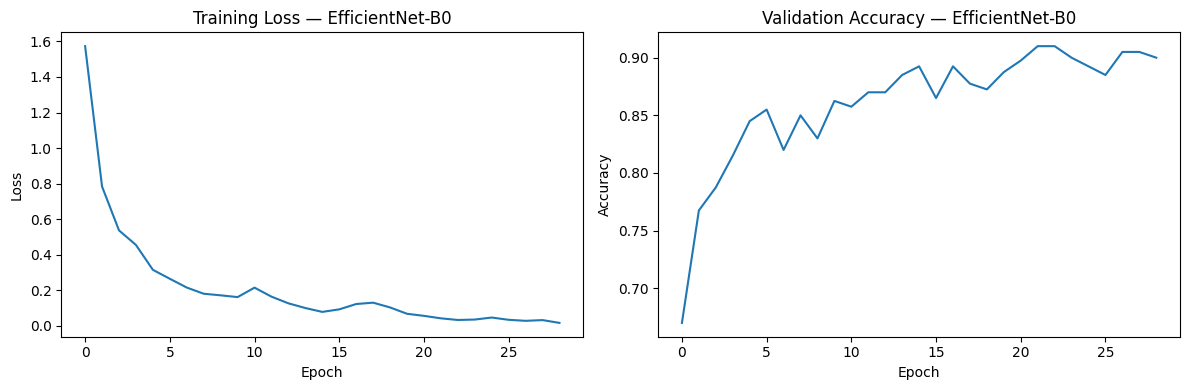

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title(f"Training Loss — {nama_terbaik}")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(valid_accs)
plt.title(f"Validation Accuracy — {nama_terbaik}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

### 7.2 Classification Report & Confusion Matrix (Test Set)

                 precision    recall  f1-score   support

Cardboard Boxes       0.88      0.95      0.91        22
  Glass Bottles       0.74      0.88      0.80        16
   Glass Shards       0.92      0.92      0.92        12
            Jug       1.00      0.93      0.97        15
      Metal Can       0.83      0.96      0.89        26
          Paper       1.00      0.75      0.86        12
      Paper Bag       0.88      0.95      0.91        22
      Paper Cup       0.74      0.82      0.78        17
 Plastic Bottle       0.86      0.75      0.80        24
    Plastic Cup       0.94      0.77      0.85        22
    Plastic bag       0.88      0.78      0.82         9
     food waste       1.00      0.90      0.95        10

       accuracy                           0.87       207
      macro avg       0.89      0.86      0.87       207
   weighted avg       0.88      0.87      0.87       207



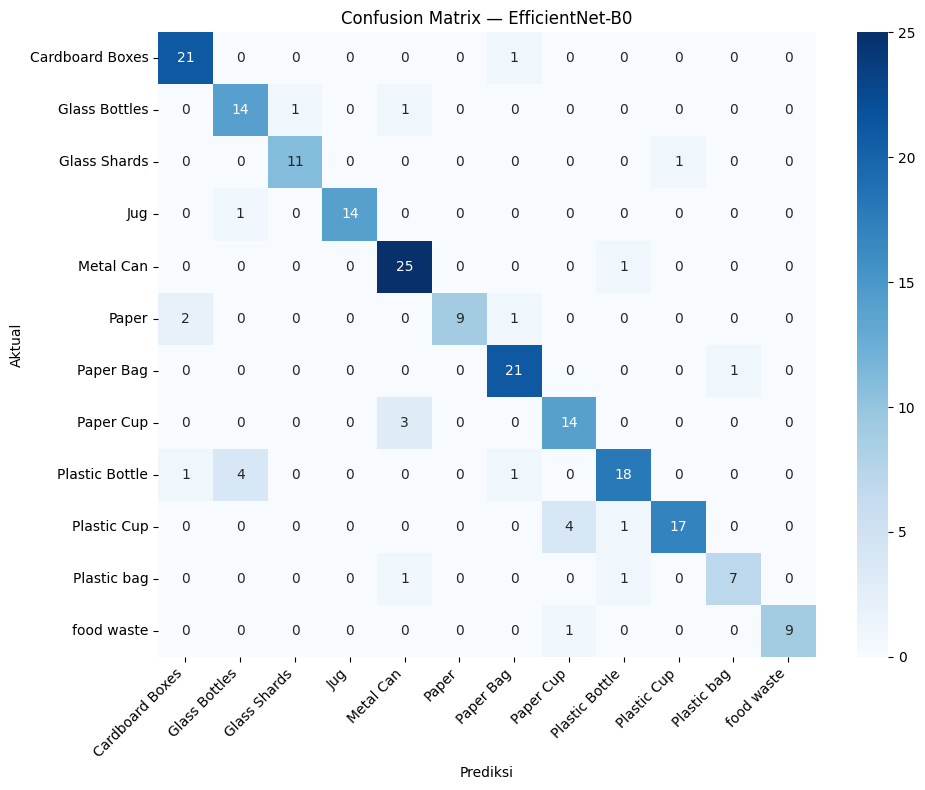

In [ ]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_ds.classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=train_ds.classes, yticklabels=train_ds.classes, cmap='Blues')
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix — {nama_terbaik}")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 7.3 Contoh Gambar yang Salah Diklasifikasi

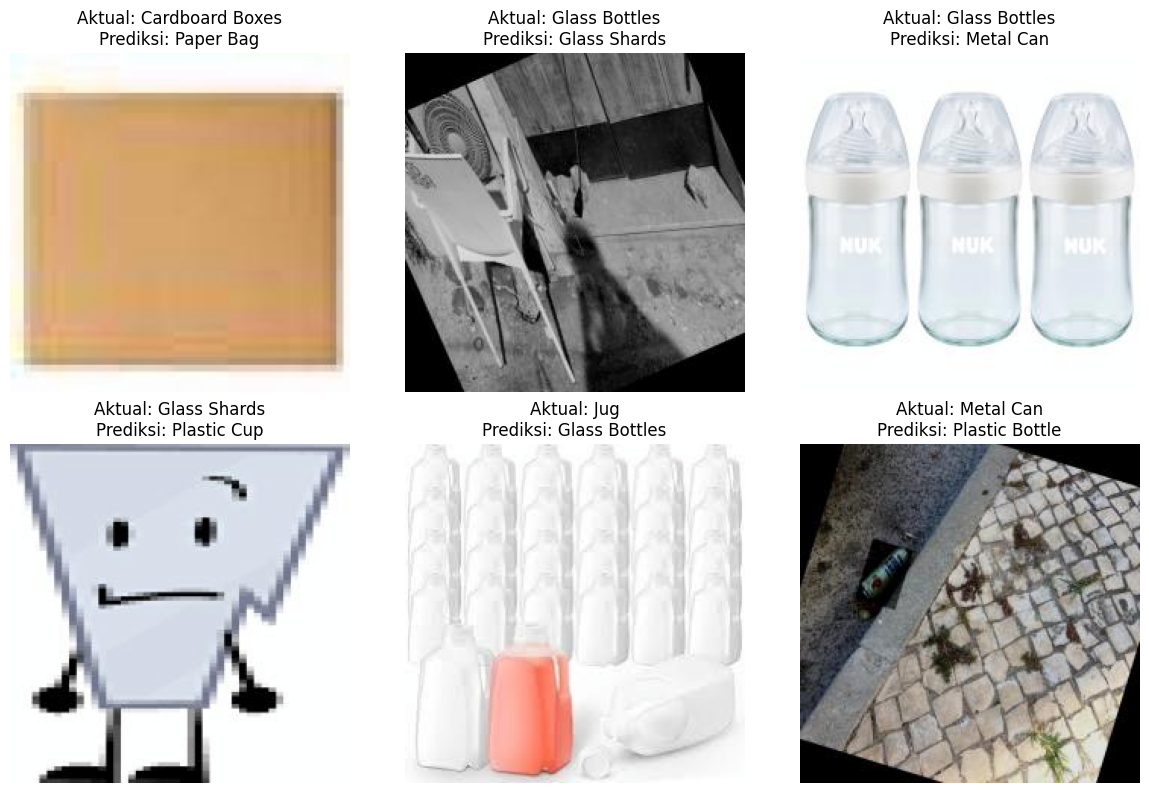

In [ ]:
wrong_samples = []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs_gpu = imgs.to(device)
        outputs = model(imgs_gpu)
        _, preds = torch.max(outputs, 1)
        for i in range(len(labels)):
            if preds[i] != labels[i]:
                wrong_samples.append((imgs[i], labels[i].item(), preds[i].item()))

n_tampil = min(6, len(wrong_samples))
if n_tampil > 0:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for idx, ax in enumerate(axes.flat):
        if idx < n_tampil:
            img, actual, pred = wrong_samples[idx]
            img = img.permute(1, 2, 0).numpy()
            img = (img * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406]
            img = np.clip(img, 0, 1)
            ax.imshow(img)
            ax.set_title(f"Aktual: {train_ds.classes[actual]}\nPrediksi: {train_ds.classes[pred]}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kesalahan klasifikasi pada test set.")

### 7.4 Ukuran Model & Kecepatan Inference

In [ ]:
size_mb = os.path.getsize(hasil_perbandingan[nama_terbaik]["path"]) / (1024 * 1024)
print(f"Ukuran model ({nama_terbaik}): {size_mb:.2f} MB")

model.eval()
times = []
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        start = time.time()
        _ = model(imgs)
        times.append((time.time() - start) / imgs.size(0))

print(f"Rata-rata waktu inference per gambar: {np.mean(times)*1000:.2f} ms")

Ukuran model (EfficientNet-B0): 15.64 MB
Rata-rata waktu inference per gambar: 0.37 ms


## 8. Test-Time Augmentation (TTA)

Fungsi opsional untuk prediksi pada satu gambar dengan beberapa variasi augmentasi ringan, hasilnya dirata-rata untuk meningkatkan keandalan prediksi. Berguna dipakai di aplikasi nanti kalau ingin akurasi ekstra saat inference (dengan trade-off waktu proses sedikit lebih lama).

In [ ]:
def predict_with_tta(model, image, n_augments=5):
    model.eval()
    predictions = []
    tta_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    with torch.no_grad():
        for _ in range(n_augments):
            img_t = tta_transform(image).unsqueeze(0).to(device)
            output = model(img_t)
            predictions.append(torch.softmax(output, dim=1))
    avg_pred = torch.mean(torch.stack(predictions), dim=0)
    return avg_pred

print("Fungsi predict_with_tta() siap dipakai. Contoh: predict_with_tta(model, gambar_PIL)")

Fungsi predict_with_tta() siap dipakai. Contoh: predict_with_tta(model, gambar_PIL)


## 9. Export Model Terbaik ke ONNX

File `.onnx` dan `labels.txt` inilah yang akan dipakai di project WPF C# (folder `Assets/Models/`), diakses lewat `Microsoft.ML.OnnxRuntime`.

In [ ]:
model.eval()
dummy_input = torch.randn(1, 3, 224, 224).to(device)

nama_file_onnx = "klasifikasi-sampah-v1.onnx"

torch.onnx.export(
    model, dummy_input, nama_file_onnx,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input"], output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
    dynamo=False
)
print(f"Model berhasil di-export ke {nama_file_onnx}")

with open("labels.txt", "w") as f:
    f.write("\n".join(train_ds.classes))
print("Daftar label disimpan ke labels.txt")

print("\nDaftar kelas (urutan sesuai output model):")
for i, kelas in enumerate(train_ds.classes):
    print(f"  {i}: {kelas}")

# 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.


[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Model berhasil di-export ke klasifikasi-sampah-v1.onnx
Daftar label disimpan ke labels.txt

Daftar kelas (urutan sesuai output model):
  0: Cardboard Boxes
  1: Glass Bottles
  2: Glass Shards
  3: Jug
  4: Metal Can
  5: Paper
  6: Paper Bag
  7: Paper Cup
  8: Plastic Bottle
  9: Plastic Cup
  10: Plastic bag
  11: food waste


## 10. Download File Hasil

Jalankan sel di bawah untuk mengunduh `klasifikasi-sampah-v1.onnx` dan `labels.txt` langsung ke komputer. Kedua file ini kemudian ditempatkan di folder `Assets/Models/` pada project WPF TRASHURY.

In [ ]:
from google.colab import files

files.download(nama_file_onnx)
files.download("labels.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>